## Загрузка данных через np.load

In [3]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load('cats_dogs_20x20.npz')

X = data['X']
y = data['y']

X = X.reshape(X.shape[0], -1)

## Делим датасет и обучаем решающее дерево

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

tree_clf = DecisionTreeClassifier(max_depth=2)
tree_clf.fit(X_train, y_train)
print("Точность решающего дерева:", tree_clf.score(X_test, y_test))

Точность решающего дерева: 1.0


In [5]:
import graphviz
from sklearn import tree
dot_data = tree.export_graphviz(tree_clf, out_file=None)
graph = graphviz.Source(dot_data)
graph.render("mytree")

'mytree.pdf'

## Масштабируем датасет и применяем метод опорных векторов

In [6]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_clf = SVC(kernel='rbf', C=1.0)
svm_clf.fit(X_train_scaled, y_train)
print("Точность метода опорных векторов", svm_clf.score(X_test_scaled, y_test))


Точность метода опорных векторов 1.0


## Решающее дерево с методом главных компонент

In [7]:
from sklearn.decomposition import PCA

pca = PCA()
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

tree_pca_clf = DecisionTreeClassifier(max_depth=2).fit(X_train_pca, y_train)
print("Точность решающего дерева с методом главных компонент:", tree_pca_clf.score(X_test_pca, y_test))

Точность решающего дерева с методом главных компонент: 0.8


In [8]:
import graphviz
from sklearn import tree
dot_data = tree.export_graphviz(tree_clf, out_file=None)
graph = graphviz.Source(dot_data)
graph.render("mytree")

'mytree.pdf'

## Ансамблевые методы

In [9]:
from sklearn.ensemble import BaggingClassifier, StackingClassifier, AdaBoostClassifier

bagging_forest_clf = BaggingClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=10)
bagging_forest_clf.fit(X_train, y_train)
print("Бэгинг:", bagging_forest_clf.score(X_test, y_test))

stacking_clf = StackingClassifier(estimators=[
    ('tree1', DecisionTreeClassifier(max_depth=2)),
    ('tree2', DecisionTreeClassifier(max_depth=2)),
    ('tree3', DecisionTreeClassifier(max_depth=2))],
    final_estimator=DecisionTreeClassifier(max_depth=2))

stacking_clf.fit(X_train, y_train)
print("Стэкинг:", stacking_clf.score(X_test, y_test))


ada_boost_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=10)
ada_boost_clf.fit(X_train, y_train)
print("Бустинг:", ada_boost_clf.score(X_test, y_test))

Бэгинг: 1.0
Стэкинг: 1.0
Бустинг: 1.0


## Изменение пикселя который изменит прогноз

In [15]:
predictions = tree_clf.predict(X_test)
correct = np.flatnonzero(predictions == y_test)

# Определяем индекс i, выбрав первый верно предсказанный объект

i = correct[0]
x = X_test[i].copy()

feature = tree_clf.tree_.feature[0]
threshold = tree_clf.tree_.threshold[0]
pixel = feature // 3

new_value = 1.0 if x[feature] <= threshold else 0.0

x_adv = x.copy()
x_adv[3 * pixel:3 * pixel + 3] = new_value

## Отображение изменённого изображения

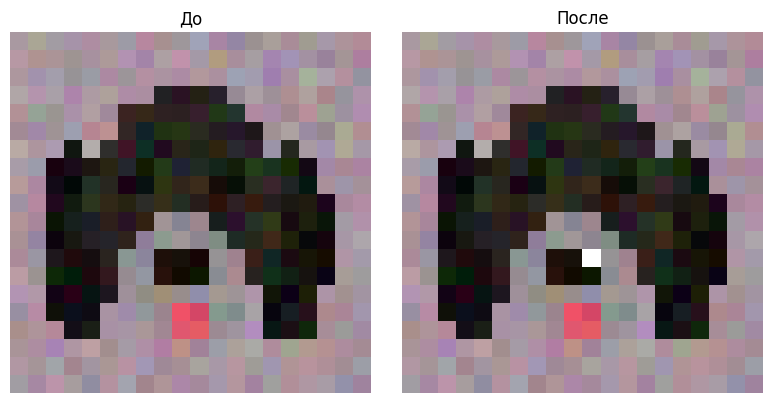

In [16]:
original_image = x.reshape(20, 20, 3)
modified_image = x_adv.reshape(20, 20, 3)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_image, interpolation="nearest")
axes[0].set_title(f"До")
axes[0].axis("off")

axes[1].imshow(modified_image, interpolation="nearest")
axes[1].set_title(f"После")
axes[1].axis("off")

plt.tight_layout()
plt.show()